# CCD Lab Analysis Example

A Notebook showing how to do some of the analysis of CCD data for the CCD lab. Copy this notebook and run all the cells yourself. 

I recommend running in Sciserver.org, but you can do it where ever you like. 

If running this at Haverford, make sure to use the `python3.10.10` kernel. 

Note that you need to have the files in the right place, and likely need to edit the `file_root` variable in the first cell to tell the computer where your files are. 

I put mine in a subdirectory called `CCDLabExampleData` in the same directory I'm running this code. 

In [38]:
#import statements may not all be needed
#Comment them out if you don't have the right module, and see if you can do the other bits! 
from astropy.io import fits
from matplotlib import pyplot as plt
import numpy as np
import os as os
from astropy import units as u

#Modules for CCD processing
import ccdproc as ccdp
from astropy.nddata import CCDData

#Nicer plot styles
from astropy.visualization import astropy_mpl_style, stretch, interval, mpl_normalize
plt.style.use(astropy_mpl_style)

#Aperture photometry 
import photutils.aperture
from photutils import CircularAperture
from photutils import aperture_photometry

#Plot inline
%matplotlib inline

# Location of data (change this to where your data are)
#file_root = "/home/idies/workspace/Storage/klmasters/persistent/ASTR341/CCDLabExampleData/"
file_root = "CCDLabExampleData/"

# Reading in FITS images and Bias Frames

In [39]:
#Import a small number of files

#Import using fit.open
bias0 = fits.open(file_root+"Bias/biasS0.FIT")
bias1 = fits.open(file_root+"Bias/biasS1.FIT")

In [40]:
#Opening as a CCD object in ccdproc also works, and 
# means you can make use of some pre-written functions. 
bias2 = CCDData.read(file_root+"Bias/biasS2.FIT", unit="adu")  

head2=bias2[0].header
head2

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                   16 / number of bits per data pixel                  
NAXIS   =                    2 / number of data axes                            
NAXIS1  =                 4096 / length of data axis 1                          
NAXIS2  =                 4096 / length of data axis 2                          
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
BZERO   =               32768. / DATA ZERO                                      
BSCALE  =                   1. / DATA SCALE                                     
EXPTIME =                   0. / duration of exposure in seconds                
XBINNING=                    1 / binning factor used on X axis                  
YBINNING=                   

In [41]:
#Extract the image data (usually in extension 0). 
#Astype(float) converts the numbers from unsigned integers to floats, which will prevent problems
#if you try to do operations which would result in negative numbers. 
biasimg0=bias0[0].data.astype(float)
biasimg1=bias1[0].data.astype(float)
biasimg2=bias2[0].data.astype(float)

print, 'Image sizes: ', biasimg0.shape,biasimg1.shape,biasimg1.shape

(<function print>, 'Image sizes: ', (4096, 4096), (4096, 4096), (4096, 4096))

In [42]:
#You can now do normal math with these arrays. E.g. Stats of the numbers in the array. 
#The difference or sum of multiple arrays. 

print('Median pixel value of a bias frame: ', np.median(biasimg0),np.median(biasimg1),np.median(biasimg2))
print('Standard deviation of pixel values in a bias frame: ', np.std(biasimg0),np.std(biasimg1),np.std(biasimg2))

average=(biasimg0+biasimg1)/2.0
#Recall this is still 4096x4096 numbers, so:
print('Median pixel value of average frame: ', np.median(average))

diff=1.0000*biasimg0-1.0000*biasimg1
diff2=1.0000*biasimg2-1.0000*biasimg1
#Recall this is still 4096x4096 numbers, so:
print('Median pixel value of difference frame (what should this be?): ', np.median(diff), np.median(diff2))
print('Standard deviation of pixel values in a difference frame: ', np.std(diff),np.std(diff2))

print('Sizes: ', diff.shape,average.shape)

print('Square of the ratio of SD of difference and single frame (what should this be?): ', (np.std(diff)/np.std(biasimg0))**2)

Median pixel value of a bias frame:  1042.0 1042.0 1042.0
Standard deviation of pixel values in a bias frame:  11.925917804841124 11.928986065109319 11.927539821978847
Median pixel value of average frame:  1042.5
Median pixel value of difference frame (what should this be?):  0.0 0.0
Standard deviation of pixel values in a difference frame:  16.385611728317766 16.55783341763992
Sizes:  (4096, 4096) (4096, 4096)
Square of the ratio of SD of difference and single frame (what should this be?):  1.887737902123201


In [43]:
#You can import a bunch of files from a list: 

#Create the list of input files
indir=file_root+'Bias/'  #Replace!
filelist=[]
for file in os.listdir(indir):
    if (file.endswith(".FIT")): 
        filelist.append(os.path.join(indir, file))

#Define the output directory (directory/folder must exist already and be in your space)
outdir='CCDLabExampleData/'
print(filelist)  #Run this command to check your list of files makes sense



['CCDLabExampleData/Bias/biasS0.FIT', 'CCDLabExampleData/Bias/biasS1.FIT', 'CCDLabExampleData/Bias/biasS2.FIT']


## Make Combined Bias in Python

In [44]:
#This command from CCDProc can do all sorts of versions of averaging. 
#This is a good way to make final best average arrays. 
#This will not overwrite a file - so you will have to change the output_file name or 
#delete the previous version to run more than once

combined_bias = ccdp.combine(filelist, unit='adu',
                             output_file=outdir+'averaged_bias.fit',overwrite=True)

print(combined_bias.shape)

OSError: File CCDLabExampleData/averaged_bias.fit already exists. If you mean to replace it then use the argument "overwrite=True".

# Plotting Images

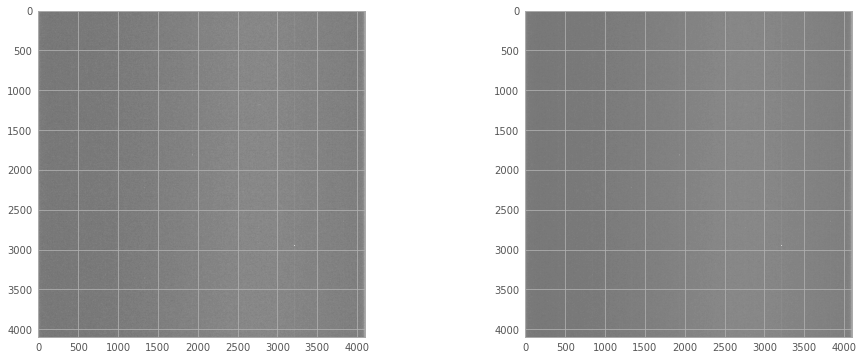

In [45]:
#You might like to reload and make a plot of the bias images. 
#Think about why the average and single frame differ. 

avbias_file=outdir+'averaged_bias.fit' 
avbias_hdul = fits.open(avbias_file)   #Read in bias image
avbias_img = avbias_hdul[0].data

bias_hdul = fits.open(filelist[0])
bias_img = bias_hdul[0].data

fig=plt.figure(figsize=(16,6))
#Plot bias image
ax1=fig.add_subplot(121)
ax1.imshow(bias_img, cmap='gray',vmin=np.median(bias_img)*0.95, vmax=np.median(bias_img)*1.05)
ax2=fig.add_subplot(122)
ax2.imshow(avbias_img, cmap='gray',vmin=np.median(bias_img)*0.95, vmax=np.median(bias_img)*1.05)

# Flat Field Images

In [46]:
#Now let's look at a flat field. Recall this is an image with uniform illumination - all pixels should have 
#had the same photon flux land on them, so any deviations are from sensitivity variations. 
#There is a wide variety of exposure times of g r and i-band flats in the test data. 

#Import Flat fields
#Create the list of input files
indir=file_root+'DomeFlatFields/'  #Replace with path to your files!
filelist=[]
for file in os.listdir(indir):
    if (file.endswith(".FIT")): 
        filelist.append(os.path.join(indir, file))
#Run this command to check your list of files makes sense
for x in filelist:
    print(x)  

CCDLabExampleData/DomeFlatFields/flat_g_1.5S2.FIT
CCDLabExampleData/DomeFlatFields/flat_g_1.5S1.FIT
CCDLabExampleData/DomeFlatFields/flat_g_2.5S2.FIT
CCDLabExampleData/DomeFlatFields/flat_g_2.5S1.FIT
CCDLabExampleData/DomeFlatFields/flat_g_0.3S2.FIT
CCDLabExampleData/DomeFlatFields/flat_g_0.3S1.FIT
CCDLabExampleData/DomeFlatFields/flat_g_0.5S2.FIT
CCDLabExampleData/DomeFlatFields/flat_g_0.5S1.FIT
CCDLabExampleData/DomeFlatFields/flat_g_4S2.FIT
CCDLabExampleData/DomeFlatFields/flat_g_4S1.FIT
CCDLabExampleData/DomeFlatFields/flat_g_3S2.FIT
CCDLabExampleData/DomeFlatFields/flat_g_3S1.FIT
CCDLabExampleData/DomeFlatFields/flat_g_2S2.FIT
CCDLabExampleData/DomeFlatFields/flat_r_2S5.FIT
CCDLabExampleData/DomeFlatFields/flat_r_2S4.FIT
CCDLabExampleData/DomeFlatFields/flat_g_2S1.FIT
CCDLabExampleData/DomeFlatFields/flat_r_2S1.FIT
CCDLabExampleData/DomeFlatFields/flat_r_2S3.FIT
CCDLabExampleData/DomeFlatFields/flat_r_2S2.FIT
CCDLabExampleData/DomeFlatFields/flat_r_1S3.FIT
CCDLabExampleData/DomeFl

File to open:  CCDLabExampleData/DomeFlatFields/flat_r_2S4.FIT
(4096, 4096)
CCD Temp: 13.0


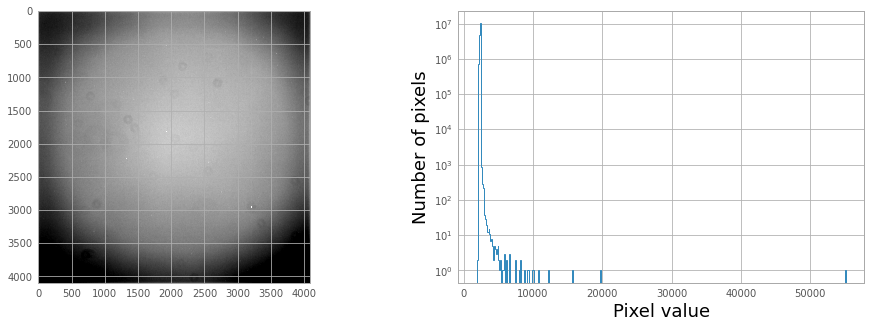

In [47]:
#Look at a single flat. You can use the backup data to find a saturated flat. 
file=filelist[14]
print('File to open: ',file)
flat_hdul = fits.open(file)   #Read in pre-subtraction image
flat_img = flat_hdul[0].data.astype(float)

fig=plt.figure(figsize=(16,5))
#Plot image
ax1=fig.add_subplot(121)
ax1.imshow(flat_img, cmap='gray',vmin=np.median(flat_img)*0.95, vmax=np.median(flat_img)*1.05)

ax2=fig.add_subplot(122)
ax2.hist(flat_img.flatten(),histtype='step',bins=500)
ax2.set_yscale('log')
ax2.set_xlabel('Pixel value',fontsize=18)
ax2.set_ylabel('Number of pixels',fontsize=18)

#Print out shape of image to make sure it's been overscan-subtracted
print(np.shape(flat_img))
print("CCD Temp:",flat_hdul[0].header["CCD-TEMP"])


In [23]:
#Import Flat fields in g-band with 4s exposure. 
#Create the list of input files
indir=file_root+'DomeFlatFields/'  #Replace with the path to your files!
filelist=[]
for file in os.listdir(indir):
    if (file.endswith(".FIT") and file.startswith("flat_g_4S") ): 
        filelist.append(os.path.join(indir, file))
#Run this command to check your list of files makes sense
for x in filelist:
    print(x)  

CCDLabExampleData/DomeFlatFields/flat_g_4S2.FIT
CCDLabExampleData/DomeFlatFields/flat_g_4S1.FIT


In [24]:
#First we remove the bias
avbias=CCDData.read(outdir+'averaged_bias.fit', unit="adu")

flat0 = CCDData.read(filelist[0], unit="adu")  #Read in pre-subtraction image
flat1 = CCDData.read(filelist[1], unit="adu")  #Read in pre-subtraction image

#Subtract the bias
reduced_flat0 = ccdp.subtract_bias(flat0, avbias)
reduced_flat1 = ccdp.subtract_bias(flat1, avbias)

reducedlist=[reduced_flat0,reduced_flat1]

INFO: using the unit adu passed to the FITS reader instead of the unit adu in the FITS file. [astropy.nddata.ccddata]


In [25]:
#This command from CCDProc can do all sorts of versions of averaging. 
#This is a good way to make final best average arrays. 
#Ideally you have more than two flats to combine

print(outdir)
gflat = ccdp.combine(reducedlist, unit='adu', sigma_clip=True,
                             output_file=outdir+'averaged_gflat4.fit')

CCDLabExampleData/


INFO: using the unit adu passed to the FITS reader instead of the unit adu in the FITS file. [astropy.nddata.ccddata]
Median pixel value of the g-band flat:  53986.166666666664
Median pixel value of the normalized g-band flat:  1.0


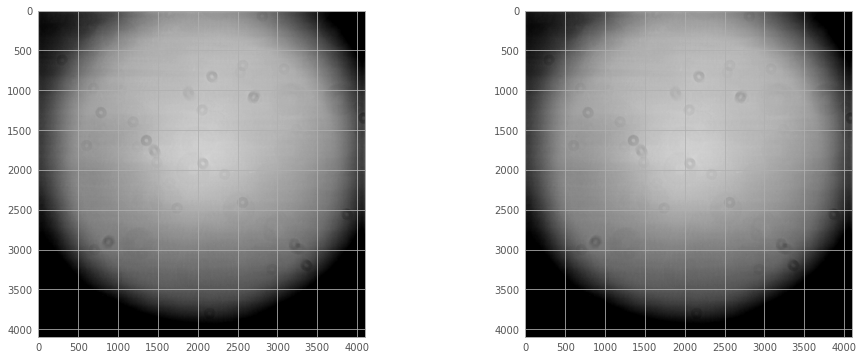

In [26]:
#Flat field normalization
avgflat=CCDData.read(outdir+'averaged_gflat4.fit', unit="adu")
print('Median pixel value of the g-band flat: ', np.median(avgflat))

normgflat=avgflat.divide(np.median(avgflat))
print('Median pixel value of the normalized g-band flat: ', np.median(normgflat))

fig=plt.figure(figsize=(16,6))
#Plot bias image
ax1=fig.add_subplot(121)
ax1.imshow(avgflat, cmap='gray',vmin=np.median(avgflat)*0.95, vmax=np.median(avgflat)*1.05)

ax2=fig.add_subplot(122)
ax2.imshow(normgflat, cmap='gray',vmin=np.median(normgflat)*0.95, vmax=np.median(normgflat)*1.05)

#However, the below CCDPROC procedure divides the flat by the median 
#before doing the correction, so we don't need to save the normalized one. 
#flatcorrected = ccdproc.flat_correct(avgflat, normgflat)
#This comment just provided for information. You don't need to do anything with it here. 

Text(0, 0.5, 'Number of pixels')

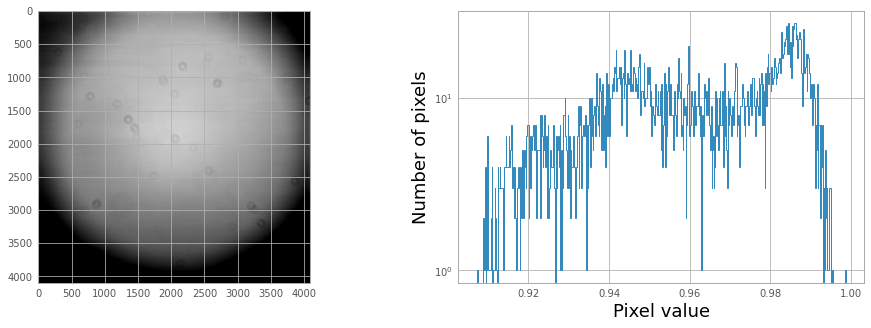

In [27]:
fig=plt.figure(figsize=(16,5))
#Plot image
ax1=fig.add_subplot(121)
ax1.imshow(normgflat, cmap='gray',vmin=np.median(normgflat)*0.95, vmax=np.median(normgflat)*1.05)

pixels=normgflat[0].data

ax2=fig.add_subplot(122)
ax2.hist(pixels.flatten(),histtype='step',bins=500)
ax2.set_yscale('log')
ax2.set_xlabel('Pixel value',fontsize=18)
ax2.set_ylabel('Number of pixels',fontsize=18)

# Measuring Gain

In [48]:
#Import Flat fields in g-band with 1 various exposure lengths. 
#Create the list of input files
indir=file_root+'DomeFlatFields/'  #Replace with the path to your files!
filelist=[]
for file in os.listdir(indir):
    if (file.endswith(".FIT") and file.startswith("flat_g") ): 
        filelist.append(os.path.join(indir, file))
#Run this command to check your list of files makes sense
for x in filelist:
    print(x)  

CCDLabExampleData/DomeFlatFields/flat_g_1.5S2.FIT
CCDLabExampleData/DomeFlatFields/flat_g_1.5S1.FIT
CCDLabExampleData/DomeFlatFields/flat_g_2.5S2.FIT
CCDLabExampleData/DomeFlatFields/flat_g_2.5S1.FIT
CCDLabExampleData/DomeFlatFields/flat_g_0.3S2.FIT
CCDLabExampleData/DomeFlatFields/flat_g_0.3S1.FIT
CCDLabExampleData/DomeFlatFields/flat_g_0.5S2.FIT
CCDLabExampleData/DomeFlatFields/flat_g_0.5S1.FIT
CCDLabExampleData/DomeFlatFields/flat_g_4S2.FIT
CCDLabExampleData/DomeFlatFields/flat_g_4S1.FIT
CCDLabExampleData/DomeFlatFields/flat_g_3S2.FIT
CCDLabExampleData/DomeFlatFields/flat_g_3S1.FIT
CCDLabExampleData/DomeFlatFields/flat_g_2S2.FIT
CCDLabExampleData/DomeFlatFields/flat_g_2S1.FIT
CCDLabExampleData/DomeFlatFields/flat_g_1S3.FIT
CCDLabExampleData/DomeFlatFields/flat_g_1S4.FIT


In [49]:
#Need to measure average and standard deviation of the difference of two of the same length. 
#T=5s is saturated so don't use. I think T=4s maybe a bit saturated too. 

#Set up for results. Times from the names of the files. Need one per PAIR of flat fields. 
#This is really bad hard coding, you would need to make it be right for your data! 
#time=[0.3,0.5,1.5,1.0,2.5,2.0,3.0]
time=[0.0,0.0,0.0,0.0,0.0,0.0,0.0]
Flux=[0.0,0.0,0.0,0.0,0.0,0.0,0.0]
SD=[0.0,0.0,0.0,0.0,0.0,0.0,0.0]

for i in range(7):
    file=filelist[2*i]
    print('File to open: ',file)
    flat1 = fits.open(file)   #Read in pre-subtraction image
    flat1_img = flat1[0].data.astype(float)
    file=filelist[2*i+1]
    print('File to open: ',file)
    flat2 = fits.open(file)   #Read in pre-subtraction image
    flat2_img = flat2[0].data.astype(float)

    time[i]=flat1[0].header["EXPTIME"]
    time2 = flat2[0].header["EXPTIME"]
    print('Exposure time in seconds (should be identical): ', time[i],time2)

    
    average=(flat1_img+flat2_img)/2.0
#Recall this is still 4096x4096 numbers, so:
    print('Median pixel value of average frame: ', np.median(average))

    diff=1.0000*flat1_img-1.0000*flat2_img
#Recall this is still 4096x4096 numbers, so:
    print('Median pixel value of difference frame (what should this be?): ', np.median(diff))
    print('Standard deviation of pixel values in a difference frame: ', np.std(diff))

    Flux[i]=np.median(average)
    SD[i]=np.std(diff)/np.sqrt(2.0)



File to open:  CCDLabExampleData/DomeFlatFields/flat_g_1.5S2.FIT
File to open:  CCDLabExampleData/DomeFlatFields/flat_g_1.5S1.FIT
Exposure time in seconds (should be identical):  1.5 1.5
Median pixel value of average frame:  21940.5
Median pixel value of difference frame (what should this be?):  66.0
Standard deviation of pixel values in a difference frame:  169.26295196818384
File to open:  CCDLabExampleData/DomeFlatFields/flat_g_2.5S2.FIT
File to open:  CCDLabExampleData/DomeFlatFields/flat_g_2.5S1.FIT
Exposure time in seconds (should be identical):  2.5 2.5
Median pixel value of average frame:  35424.0
Median pixel value of difference frame (what should this be?):  121.0
Standard deviation of pixel values in a difference frame:  213.37104180532754
File to open:  CCDLabExampleData/DomeFlatFields/flat_g_0.3S2.FIT
File to open:  CCDLabExampleData/DomeFlatFields/flat_g_0.3S1.FIT
Exposure time in seconds (should be identical):  0.3 0.3
Median pixel value of average frame:  5536.0
Median 

[1.5, 2.5, 0.3, 0.5, 4.0, 3.0, 2.0] [21940.5, 35424.0, 5536.0, 8255.0, 55028.0, 42195.5, 28728.0] [119.68698114035567, 150.87611056938542, 57.26432206904291, 71.56211809259246, 179.46291538767522, 162.4635019119278, 136.82454513706605]
Fitted line y=ax+b:  [5.97689085e-01 7.14642100e+02]
Pixel gain should be the inverse of the slope of this line, or,  1.6731106950584107


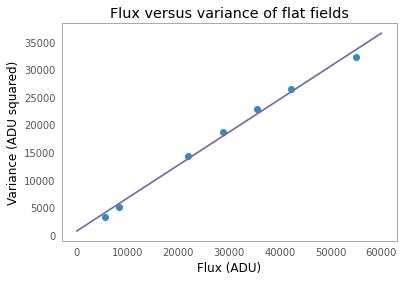

In [50]:
#Debugging line
print(time,Flux,SD)
#Time=Time*60.0

Var=np.square(SD)


fit = np.polyfit(Flux, Var, 1)
print("Fitted line y=ax+b: ", fit)
print('Pixel gain should be the inverse of the slope of this line, or, ', 1/fit[0])
#print("Manufactorer reported value is 2.63 electrons/ADU")
a=fit[0]
b=fit[1]
x=np.linspace(0,60000,1000)
y = a*x+b

#Make a plot
plt.plot(Flux,Var,'o')
plt.plot(x,y)

#Title
plt.title('Flux versus variance of flat fields')

#Axis labels
plt.xlabel("Flux (ADU)")
plt.ylabel("Variance (ADU squared)")

#Add a grid
plt.grid()

#Add a legend box
#plt.legend()

#Actually show the plot
plt.show()